# 5. Linear programming

Portfolio exercises 5.1–5.3 ([CO 12.1, 13.1, 14.3.1]). Section 5.1 solves a
two-variable LP and looks at its vertices, level lines and active constraints as
the objective rotates. Section 5.2 puts the same LP in standard form, derives
its dual by hand, checks weak and strong duality and reads the shadow prices of
the three constraints. Section 5.3 solves the max-flow LP of [CO 13.1] and shows
that its dual is the min-cut.

Every LP is solved with `scipy.optimize.linprog` and, where possible, also by
hand; the optimality claims (vertex optimality, complementary slackness, weak
and strong duality, max flow = min cut) are checked numerically next to where
they are used. Random experiments use `rng = np.random.default_rng(2026)`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from scipy.optimize import linprog
import networkx as nx

rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.figsize": (7, 4.2), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 9})

## 5.1 An LP you can see [CO 12.1]

### Task

Solve
$$\max_x\; 3x_1+2x_2 \quad\text{s.t.}\quad x_1+x_2\le4,\quad x_1+3x_2\le6,\quad x_1\le3,\quad x\ge0$$
with `scipy.optimize.linprog`. Plot the feasible polygon, the level lines of the
objective, its gradient $c$ and the optimal vertex. Mark all vertices with their
objective value.

### Explore

Rotate $c$ with a slider (angle $\theta$). Make $c$ parallel to an edge. Remove a
constraint so that the problem becomes unbounded; add one that makes it
infeasible.

In [2]:
c51 = np.array([3.0, 2.0])                      # maximise c51 . x
A51 = np.array([[1.0, 1.0],                     # x1 + x2 <= 4
                [1.0, 3.0],                     # x1 + 3 x2 <= 6
                [1.0, 0.0]])                    # x1 <= 3
b51 = np.array([4.0, 6.0, 3.0])


def solve51(c):
    """Maximise c . x over the polygon; return (x, value, result)."""
    res = linprog(-c, A_ub=A51, b_ub=b51, bounds=[(0, None)] * 2, method="highs")
    assert res.status == 0, res.message
    return res.x, -res.fun, res


x51, p51, res51 = solve51(c51)
print(f"x* = {x51},   p* = {p51:.6f}")

# A vertex is the intersection of two boundary lines; keep the feasible ones.
lines = [np.array([1.0, 0.0]), np.array([0.0, 1.0])] + list(A51)   # x1 >= 0, x2 >= 0
rhs = [0.0, 0.0] + list(b51)
verts = []
for i in range(len(lines)):
    for j in range(i + 1, len(lines)):
        M = np.array([lines[i], lines[j]])
        if abs(np.linalg.det(M)) < 1e-12:
            continue
        x = np.linalg.solve(M, [rhs[i], rhs[j]])
        if (A51 @ x <= b51 + 1e-9).all() and (x >= -1e-9).all():
            verts.append(np.round(x, 12))
verts = np.unique(verts, axis=0)
# order them around the centroid, otherwise Polygon() draws a bow-tie
centre = verts.mean(axis=0)
verts = verts[np.argsort(np.arctan2((verts - centre)[:, 1], (verts - centre)[:, 0]))]
for x in verts:
    print(f"  vertex ({x[0]:.0f}, {x[1]:.0f})  ->  3x1 + 2x2 = {c51 @ x:.3f}")

assert np.isclose(max(c51 @ x for x in verts), p51)          # the best vertex is optimal
assert np.allclose(x51, verts[np.argmax([c51 @ x for x in verts])])
print("active constraints at x* (b - A x*):", (b51 - A51 @ x51).round(12))

x* = [3. 1.],   p* = 11.000000
  vertex (0, 0)  ->  3x1 + 2x2 = 0.000
  vertex (3, 0)  ->  3x1 + 2x2 = 9.000
  vertex (3, 1)  ->  3x1 + 2x2 = 11.000
  vertex (0, 2)  ->  3x1 + 2x2 = 4.000
active constraints at x* (b - A x*): [0. 0. 0.]


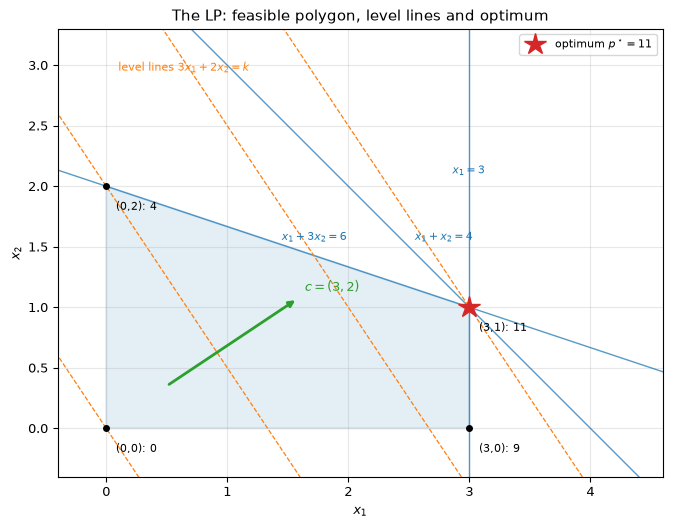

In [3]:
fig, ax = plt.subplots(figsize=(6.8, 5.4))
ax.add_patch(Polygon(verts, closed=True, facecolor="tab:blue", alpha=0.12,
                     edgecolor="tab:blue", lw=1.6))

# the three constraint lines
g = np.linspace(-0.6, 4.8, 300)
for (a1, a2), bb in zip(A51, b51):
    if abs(a2) > 1e-12:
        ax.plot(g, (bb - a1 * g) / a2, color="tab:blue", lw=1.0, alpha=0.75)
    else:
        ax.axvline(bb / a1, color="tab:blue", lw=1.0, alpha=0.75)
ax.text(2.55, 1.55, r"$x_1+x_2=4$", color="tab:blue", fontsize=8)
ax.text(1.45, 1.55, r"$x_1+3x_2=6$", color="tab:blue", fontsize=8)
ax.text(2.86, 2.10, r"$x_1=3$", color="tab:blue", fontsize=8)

# level lines of the objective
for k in [0.0, 4.0, 8.0, 11.0]:
    ax.plot(g, (k - c51[0] * g) / c51[1], ls="--", lw=0.9, color="tab:orange")
ax.text(0.10, 2.95, r"level lines $3x_1+2x_2=k$", color="tab:orange", fontsize=8)

# gradient of the objective
s = 1.3 / np.linalg.norm(c51)
ax.annotate("", xy=(0.5 + s * c51[0], 0.35 + s * c51[1]), xytext=(0.5, 0.35),
            arrowprops=dict(arrowstyle="-|>", color="tab:green", lw=2.0))
ax.text(0.5 + s * c51[0] + 0.06, 0.35 + s * c51[1] + 0.06, r"$c=(3,2)$",
        color="tab:green", fontsize=9)

for x in verts:
    ax.plot(*x, "o", color="k", ms=4)
    ax.annotate(f"({x[0]:.0f},{x[1]:.0f}): {c51 @ x:.0f}", xy=x,
                xytext=(7, -17), textcoords="offset points", fontsize=8)
ax.plot(*x51, "*", color="tab:red", ms=16, label=rf"optimum $p^\star={p51:.0f}$")
ax.set_xlim(-0.4, 4.6); ax.set_ylim(-0.4, 3.3); ax.set_aspect("equal")
ax.set_xlabel(r"$x_1$"); ax.set_ylabel(r"$x_2$")
ax.set_title("The LP: feasible polygon, level lines and optimum")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()

tan θ = 3 at θ = 71.565051°; there the whole edge (3,1)-(0,2) is optimal
  θ =   0.000°: x* = (3.000, 0.000), p* = 3.0000
  θ =  20.000°: x* = (3.000, 1.000), p* = 3.1611
  θ =  50.000°: x* = (3.000, 1.000), p* = 2.6944
  θ =  71.565°: x* = (3.000, 1.000), p* = 1.8974
  θ =  85.000°: x* = (0.000, 2.000), p* = 1.9924
  θ =  90.000°: x* = (0.000, 2.000), p* = 2.0000


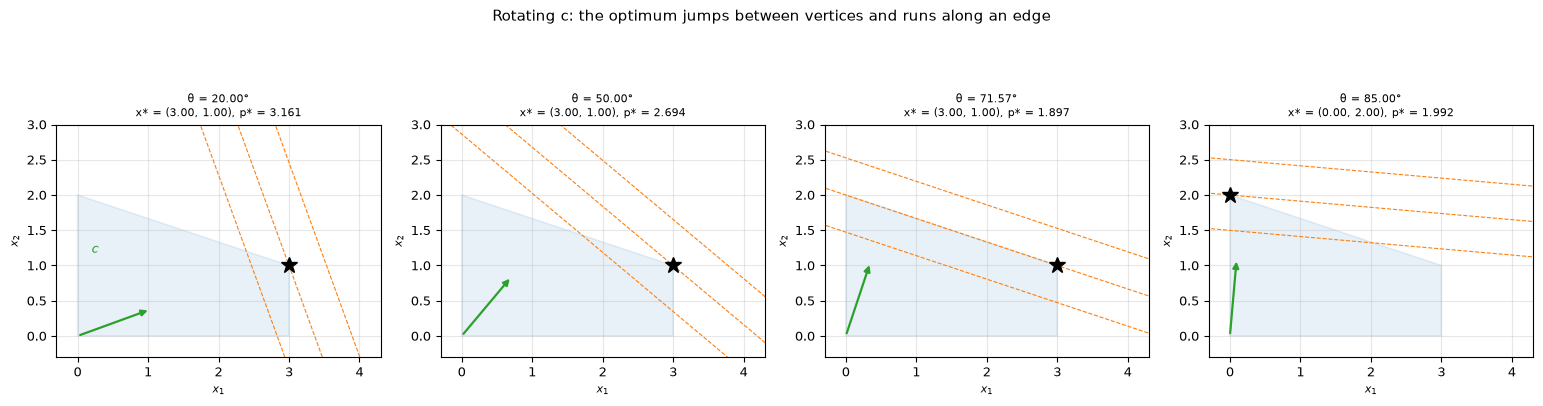

In [4]:
angles = [20.0, 50.0, np.degrees(np.arctan(3.0)), 85.0]
fig, axes = plt.subplots(1, 4, figsize=(15.5, 4.1))
for ax, deg in zip(axes, angles):
    th = np.deg2rad(deg)
    c = np.array([np.cos(th), np.sin(th)])
    x, p, _ = solve51(c)
    ax.add_patch(Polygon(verts, closed=True, facecolor="tab:blue", alpha=0.10,
                         edgecolor="tab:blue", lw=1.2))
    for k in [p - 0.5, p, p + 0.5]:
        ax.plot(g, (k - c[0] * g) / c[1], ls="--", lw=0.8, color="tab:orange")
    ax.annotate("", xy=(1.1 * c[0], 1.1 * c[1]), xytext=(0.0, 0.0),
                arrowprops=dict(arrowstyle="-|>", color="tab:green", lw=1.6))
    ax.plot(*x, "k*", ms=12)
    ax.set_title(f"θ = {deg:.2f}°\nx* = ({x[0]:.2f}, {x[1]:.2f}), p* = {p:.3f}", fontsize=8)
    ax.set_xlim(-0.3, 4.3); ax.set_ylim(-0.3, 3.0); ax.set_aspect("equal")
    ax.set_xlabel(r"$x_1$", fontsize=8); ax.set_ylabel(r"$x_2$", fontsize=8)
axes[0].text(0.20, 1.18, r"$c$", color="tab:green", fontsize=9)
fig.suptitle("Rotating c: the optimum jumps between vertices and runs along an edge", y=1.03)
plt.tight_layout()

th_star = np.arctan(3.0)
print(f"tan θ = 3 at θ = {np.degrees(th_star):.6f}°; there the whole edge (3,1)-(0,2) is optimal")
for deg in [0.0, 20.0, 50.0, np.degrees(th_star), 85.0, 90.0]:
    th = np.deg2rad(deg)
    c = np.array([np.cos(th), np.sin(th)])
    x, p, _ = solve51(c)
    print(f"  θ = {deg:7.3f}°: x* = ({x[0]:.3f}, {x[1]:.3f}), p* = {p:.4f}")

c20 = np.array([np.cos(np.deg2rad(20.0)), np.sin(np.deg2rad(20.0))])
assert np.allclose(solve51(c20)[0], [3.0, 1.0])
c_edge = np.array([np.cos(th_star), np.sin(th_star)])
p_edge = solve51(c_edge)[1]
assert np.isclose(p_edge, c_edge @ np.array([3.0, 1.0]))      # (3,1)
assert np.isclose(p_edge, c_edge @ np.array([0.0, 2.0]))      # (0,2)
assert np.isclose(p_edge, 6 / np.sqrt(10))
p_x1 = solve51(np.array([1.0, 0.0]))[1]
assert np.isclose(p_x1, 3.0) and np.isclose(p_x1, np.array([1.0, 0.0]) @ [3.0, 1.0])
c85 = np.array([np.cos(np.deg2rad(85.0)), np.sin(np.deg2rad(85.0))])
assert np.allclose(solve51(c85)[0], [0.0, 2.0])

In [5]:
import ipywidgets as widgets
from ipywidgets import interact


def panel51(angle_deg=30.0):
    th = np.deg2rad(angle_deg)
    c = np.array([np.cos(th), np.sin(th)])
    x, p, _ = solve51(c)
    fig, ax = plt.subplots(figsize=(6.2, 4.8))
    ax.add_patch(Polygon(verts, closed=True, facecolor="tab:blue", alpha=0.10,
                         edgecolor="tab:blue", lw=1.2))
    for k in [p - 0.6, p, p + 0.6]:
        if abs(c[1]) > 1e-9:
            ax.plot(g, (k - c[0] * g) / c[1], ls="--", lw=0.8, color="tab:orange")
        else:
            ax.axvline(k / c[0], ls="--", lw=0.8, color="tab:orange")
    ax.annotate("", xy=(1.1 * c[0], 1.1 * c[1]), xytext=(0.0, 0.0),
                arrowprops=dict(arrowstyle="-|>", color="tab:green", lw=1.6))
    ax.plot(*x, "k*", ms=12)
    ax.set_xlim(-0.3, 4.3); ax.set_ylim(-0.3, 3.0); ax.set_aspect("equal")
    ax.set_xlabel(r"$x_1$"); ax.set_ylabel(r"$x_2$")
    ax.set_title(f"θ = {angle_deg:.1f}°, x* = ({x[0]:.2f}, {x[1]:.2f}), p* = {p:.3f}")
    plt.show()


interact(panel51, angle_deg=widgets.FloatSlider(value=30.0, min=0.0, max=90.0, step=0.5,
         description="θ (°)", continuous_update=False,
         layout=widgets.Layout(width="380px")));

interactive(children=(FloatSlider(value=30.0, continuous_update=False, description='θ (°)', layout=Layout(widt…

keep only x1 <= 3: 3 - The problem is unbounded. (HiGHS Status 10: model_status is Unbounded; primal_status is Feasible)
add x1 >= 5: 2 - The problem is infeasible. (HiGHS Status 8: model_status is Infeasible; primal_status is None)
removing one original constraint at a time:
  without constraint 1: status 0, p* = 11.000
  without constraint 2: status 0, p* = 11.000
  without constraint 3: status 0, p* = 12.000


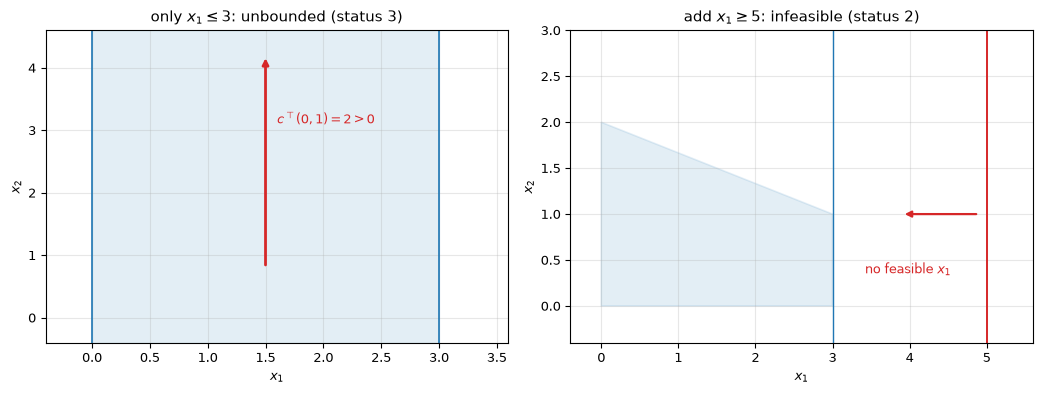

In [6]:
res_unb = linprog(-c51, A_ub=A51[2:], b_ub=b51[2:], bounds=[(0, None)] * 2,
                  method="highs")
A_inf = np.vstack([A51, [-1.0, 0.0]])          # add x1 >= 5
b_inf = np.r_[b51, -5.0]
res_inf = linprog(-c51, A_ub=A_inf, b_ub=b_inf, bounds=[(0, None)] * 2, method="highs")
print("keep only x1 <= 3:", res_unb.status, "-", res_unb.message)
print("add x1 >= 5:", res_inf.status, "-", res_inf.message)
assert res_unb.status == 3 and res_inf.status == 2

print("removing one original constraint at a time:")
for k in range(3):
    keep = [i for i in range(3) if i != k]
    r = linprog(-c51, A_ub=A51[keep], b_ub=b51[keep], bounds=[(0, None)] * 2, method="highs")
    print(f"  without constraint {k + 1}: status {r.status}, p* = {-r.fun:.3f}")
    assert r.status == 0

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.0))
axes[0].axvspan(0, 3, color="tab:blue", alpha=0.12)
axes[0].axvline(0, color="tab:blue", lw=1.2)
axes[0].axvline(3, color="tab:blue", lw=1.2)
axes[0].annotate("", xy=(1.5, 4.2), xytext=(1.5, 0.8),
                 arrowprops=dict(arrowstyle="-|>", color="tab:red", lw=2.0))
axes[0].text(1.6, 3.1, r"$c^\top(0,1)=2>0$", color="tab:red", fontsize=9)
axes[0].set_xlim(-0.4, 3.6); axes[0].set_ylim(-0.4, 4.6)
axes[0].set_xlabel(r"$x_1$"); axes[0].set_ylabel(r"$x_2$")
axes[0].set_title(r"only $x_1\leq3$: unbounded (status 3)")

axes[1].add_patch(Polygon(verts, closed=True, facecolor="tab:blue", alpha=0.12,
                          edgecolor="tab:blue", lw=1.2))
axes[1].axvline(3, color="tab:blue", lw=1.0)
axes[1].axvline(5, color="tab:red", lw=1.4)
axes[1].annotate("", xy=(3.9, 1.0), xytext=(4.9, 1.0),
                 arrowprops=dict(arrowstyle="-|>", color="tab:red", lw=1.6))
axes[1].text(3.42, 0.35, "no feasible $x_1$", color="tab:red", fontsize=9)
axes[1].set_xlim(-0.4, 5.6); axes[1].set_ylim(-0.4, 3.0)
axes[1].set_xlabel(r"$x_1$"); axes[1].set_ylabel(r"$x_2$")
axes[1].set_title(r"add $x_1\geq5$: infeasible (status 2)")
plt.tight_layout()

### Explain

The optimum is the vertex $(3,1)$ with $p^\star=11$; the four vertices carry
$0,4,9,11$ and `linprog` returns the best one. With $c=(\cos\theta,\sin\theta)$
the optimum stays at $(3,1)$ for $0<\theta<\arctan3=71.565^\circ$; at
$\tan\theta=3$ the level lines are parallel to the edge from $(3,1)$ to
$(0,2)$, so every point of that edge is optimal, and for $\theta>71.565^\circ$
the optimum is $(0,2)$. At $\theta=0$ the optimal face is the edge $x_1=3$
(value $3$). Hence the optimum is a vertex unless $c$ is normal to an edge, and
then the whole edge is optimal. At $(3,1)$ all three constraints are active
(residuals $0,0,0$) while $x\ge0$ is not: three active constraints in 2-D is a
degenerate vertex, which is why the dual optimum in 5.2 is not unique. Dropping
$x_1\le3$ alone keeps the LP bounded ($p^\star=12$ at $(4,0)$); dropping the
two flow constraints leaves the strip $0\le x_1\le3$, $x_2\ge0$, where it is
unbounded (status 3). Adding $x_1\ge5$ makes it infeasible (status 2).

## 5.2 Weak and strong duality for LPs [CO 12.1, 14.3.1]

### Task

Write the LP of 5.1 in standard form (slack variables, [CO 12.1]) and derive its
dual by hand, then using [CO 14.3.1]. Solve primal and dual with `linprog` and
also read the dual variables in `res.ineqlin.marginals`. For random feasible
$x$ and $y$, plot $c^\top x$ and $b^\top y$.

### Explore

Check $c^\top x\ge b^\top y$ for every feasible pair (weak duality) and equality
at the optimum (strong duality). Interpret each dual variable as the change in
the optimum when the right-hand side of its constraint is increased by one
(check it by re-solving).

In [7]:
A_std = np.hstack([A51, np.eye(3)])          # z = (x1, x2, s1, s2, s3)
c_std = np.concatenate([-c51, np.zeros(3)])
res_std = linprog(c_std, A_eq=A_std, b_eq=b51, bounds=[(0, None)] * 5, method="highs")
z = res_std.x
print("z = (x1, x2, s1, s2, s3) =", z)
print(f"primal minimum = {res_std.fun:.6f}")
assert res_std.status == 0
assert np.allclose(A_std @ z, b51)                 # Ax + s = b
assert np.allclose(z[:2], [3.0, 1.0])              # the same x* as in 5.1
assert np.isclose(-res_std.fun, p51)

z = (x1, x2, s1, s2, s3) = [3. 1. 0. 0. 0.]
primal minimum = -11.000000


### The dual by hand

With $z=(x_1,x_2,s_1,s_2,s_3)$ the standard form is
$$\min_z\;(-3,-2,0,0,0)^\top z\quad\text{s.t.}\quad
\begin{pmatrix}1&1&1&0&0\\1&3&0&1&0\\1&0&0&0&1\end{pmatrix}z=(4,6,3),\quad z\ge0.$$
[CO 14.3.1] gives the dual $\max_y b^\top y$ subject to $A^\top y\le c$, that is
$$y_1+y_2+y_3\le-3,\quad y_1+3y_2\le-2,\quad y_1\le0,\quad y_2\le0,\quad y_3\le0.$$
Setting $\lambda=-y\ge0$ turns this into the usual dual of the max problem,
$$\min_\lambda 4\lambda_1+6\lambda_2+3\lambda_3\quad\text{s.t.}\quad
\lambda_1+\lambda_2+\lambda_3\ge3,\;\lambda_1+3\lambda_2\ge2,\;\lambda\ge0.$$
At the optimum both inequalities are equalities, so
$\lambda(t)=(2-3t,\,t,\,1+2t)$ with $0\le t\le2/3$, and every point of this
segment has $b^\top\lambda=11$. The dual optimum is therefore not unique: the
primal vertex $(3,1)$ is degenerate, with three active constraints in 2-D.

In [8]:
y = res_std.eqlin.marginals               # dual variables of the three equalities
lam = -y
print("y =", y, "   lambda = -y =", lam)
print("res51.ineqlin.marginals =", res51.ineqlin.marginals,
      "  -> lambda =", -res51.ineqlin.marginals)
assert np.allclose(-res51.ineqlin.marginals, lam)   # same dual variables on the A_ub form
assert (A_std.T @ y <= c_std + 1e-12).all()        # dual feasibility: A^T y <= c
assert (lam >= -1e-12).all()
assert np.isclose(b51 @ y, res_std.fun)            # b^T y = -p*

res_dual = linprog(b51, A_ub=-A51.T, b_ub=-c51, bounds=[(0, None)] * 3, method="highs")
print("dual LP: lambda =", res_dual.x, f"   b.lambda = {res_dual.fun:.6f}")
assert res_dual.status == 0
assert (A51.T @ res_dual.x >= c51 - 1e-12).all()   # dual feasibility
assert np.isclose(res_dual.fun, -res_std.fun)      # strong duality

s = b51 - A51 @ z[:2]
print("slacks s =", s, "   lambda * s =", lam * s)
assert np.allclose(lam * s, 0)                     # complementary slackness
assert np.isclose(lam @ b51, -res_std.fun)         # b^T lambda = p*

y = [-0.         -0.66666667 -2.33333333]    lambda = -y = [0.         0.66666667 2.33333333]
res51.ineqlin.marginals = [-0.         -0.66666667 -2.33333333]   -> lambda = [0.         0.66666667 2.33333333]
dual LP: lambda = [2. 0. 1.]    b.lambda = 11.000000
slacks s = [0. 0. 0.]    lambda * s = [0. 0. 0.]


c.x in [0.225, 10.905],   b.lambda in [11.146, 26.556]
gap in [2.199, 24.636], mean 10.908


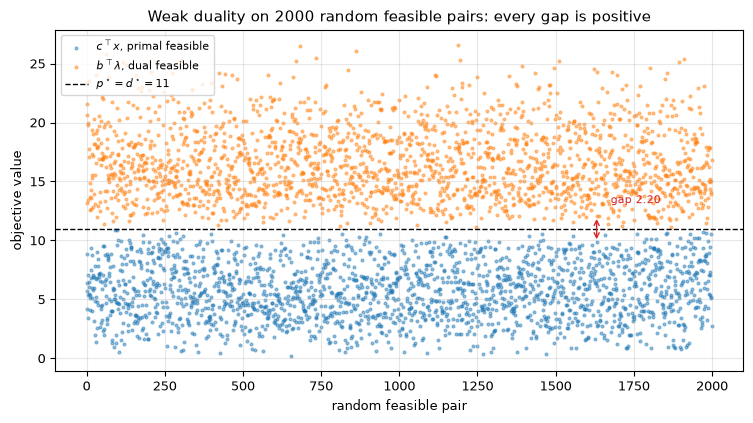

In [9]:
n52 = 2000
X = rng.uniform([0.0, 0.0], [3.0, 2.0], size=(300000, 2))
X = X[(X @ A51.T <= b51 + 1e-12).all(axis=1)][:n52]
Lam = rng.uniform(0.0, [3.0, 1.0, 3.0], size=(600000, 3))
Lam = Lam[(Lam @ A51 >= c51 - 1e-12).all(axis=1)][:n52]
vx, vy = X @ c51, Lam @ b51
gap = vy - vx
print(f"c.x in [{vx.min():.3f}, {vx.max():.3f}],   b.lambda in [{vy.min():.3f}, {vy.max():.3f}]")
print(f"gap in [{gap.min():.3f}, {gap.max():.3f}], mean {gap.mean():.3f}")
assert (gap >= -1e-9).all() and vx.max() <= 11 + 1e-9 and vy.min() >= 11 - 1e-9

fig, ax = plt.subplots(figsize=(7.6, 4.3))
ax.scatter(np.arange(n52), vx, s=4, alpha=0.45, label=r"$c^\top x$, primal feasible")
ax.scatter(np.arange(n52), vy, s=4, alpha=0.45, label=r"$b^\top\lambda$, dual feasible")
ax.axhline(11, color="k", lw=1.0, ls="--", label=r"$p^\star=d^\star=11$")
i = int(np.argmin(gap))
ax.annotate("", xy=(i, vy[i]), xytext=(i, vx[i]),
            arrowprops=dict(arrowstyle="<->", color="tab:red", lw=1.0))
ax.text(i + 45, vy[i] + 1.1, f"gap {gap[i]:.2f}", color="tab:red", fontsize=8)
ax.set_xlabel("random feasible pair")
ax.set_ylabel("objective value")
ax.set_title("Weak duality on 2000 random feasible pairs: every gap is positive")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()

In [10]:
t = np.linspace(0.0, 2 / 3, 1001)
face = np.stack([2 - 3 * t, t, 1 + 2 * t], axis=1)
assert np.allclose(face @ b51, 11)                 # every point is dual optimal
assert (face >= -1e-12).all() and (face @ A51 >= c51 - 1e-12).all()
lo, hi = face.min(axis=0), face.max(axis=0)
print("shadow-price interval [min, max] over the optimal dual face")
for i in range(3):
    print(f"  lambda_{i + 1} in [{lo[i]:.6f}, {hi[i]:.6f}]")

print("\n i   p*(b+e_i)-p*   p*(b-e_i)-p*   min lambda_i   max lambda_i   linprog lambda_i")
plus, minus = [], []
for i in range(3):
    pv = []
    for sign in (+1, -1):
        bb = b51.copy()
        bb[i] += sign
        r = linprog(-c51, A_ub=A51, b_ub=bb, bounds=[(0, None)] * 2, method="highs")
        pv.append(-r.fun - 11)
    plus.append(pv[0])
    minus.append(pv[1])
    print(f" {i + 1}    {pv[0]:+.6f}        {pv[1]:+.6f}       {lo[i]:.6f}       {hi[i]:.6f}       {lam[i]:.6f}")
assert np.allclose(plus, lo) and np.allclose(minus, -hi)

shadow-price interval [min, max] over the optimal dual face
  lambda_1 in [0.000000, 2.000000]
  lambda_2 in [0.000000, 0.666667]
  lambda_3 in [1.000000, 2.333333]

 i   p*(b+e_i)-p*   p*(b-e_i)-p*   min lambda_i   max lambda_i   linprog lambda_i
 1    +0.000000        -2.000000       0.000000       2.000000       0.000000
 2    +0.000000        -0.666667       0.000000       0.666667       0.666667
 3    +1.000000        -2.333333       1.000000       2.333333       2.333333


### Explain

Strong duality holds: standard form and dual both attain $11$. Over 2000 random
feasible pairs $c^\top x$ reaches $10.905$ and $b^\top\lambda$ starts at
$11.146$, so every observed gap is positive, the smallest being $2.199$. At the
optimum all three slacks vanish and $\lambda\cdot s=0$; the marginals
$\lambda=(0,0.667,2.333)$ satisfy $A^\top\lambda\ge c$ and $b^\top\lambda=11$. But
$(3,1)$ is degenerate, so the dual optimum is the segment
$\lambda(t)=(2-3t,t,1+2t)$, $0\le t\le2/3$, and a shadow price is an interval
rather than a number: raising $b_3$ by one raises $p^\star$ by $1=\min_t\lambda_3$,
while $b_1$ and $b_2$ do not change it; lowering $b_1,b_2,b_3$ by one changes
$p^\star$ by $2,0.667,2.333$, the maxima over the segment. The `linprog`
marginals are one point of the segment (the upper end for $\lambda_2$ and
$\lambda_3$), so they match the $+1$ change only for $\lambda_1$.

## 5.3 Max flow and min cut [CO 13.1]

### Task

Reproduce the graph of [CO 13.1]: nodes $s,1,2,t$ and edges
$(s,1),(s,2),(1,2),(1,t),(2,t)$ with capacities $c=(4,2,2,3,5)$. Solve the
max-flow LP
$$\max_f\; f_{s1}+f_{s2}\quad\text{s.t.}\quad Af=0,\quad 0\le f\le c,$$
with $A$ the two conservation rows of [CO 13.1], draw the graph labelling each
edge with $f_{uv}/c_{uv}$, and enumerate the four cuts $S_1,\dots,S_4$ with
their capacities. Compare with `networkx.maximum_flow` and `minimum_cut`.

### Explore

Change the capacities with sliders and watch which cut is minimal. Build a
larger random graph.

In [11]:
edges53 = [("s", "1"), ("s", "2"), ("1", "2"), ("1", "t"), ("2", "t")]
cap53 = np.array([4.0, 2.0, 2.0, 3.0, 5.0])
E53 = len(edges53)
j53 = {e: k for k, e in enumerate(edges53)}

A53 = np.zeros((2, E53))                       # conservation at nodes 1 and 2
A53[0, j53[("s", "1")]] = 1.0
A53[0, j53[("1", "2")]] = -1.0
A53[0, j53[("1", "t")]] = -1.0
A53[1, j53[("s", "2")]] = 1.0
A53[1, j53[("1", "2")]] = 1.0
A53[1, j53[("2", "t")]] = -1.0
b53 = np.array([1.0, 1.0, 0.0, 0.0, 0.0])      # net flow out of s

res53 = linprog(-b53, A_eq=A53, b_eq=np.zeros(2), bounds=[(0, c) for c in cap53],
                method="highs")
f53 = res53.x
print("A =", A53.tolist())
print("f =", f53, "   total flow =", -res53.fun)
assert res53.status == 0
assert np.allclose(A53 @ f53, 0)                          # conservation
assert (f53 >= -1e-9).all() and (f53 <= cap53 + 1e-9).all()


def cut_capacity(caps, S):
    return sum(caps[k] for k, (u, v) in enumerate(edges53) if u in S and v not in S)


cuts53 = [{"s"}, {"s", "1"}, {"s", "2"}, {"s", "1", "2"}]
for S in cuts53:
    print(f"  cut {sorted(S)}: capacity {cut_capacity(cap53, S):.0f}")
best_cut = min(cut_capacity(cap53, S) for S in cuts53)
assert np.isclose(best_cut, -res53.fun)                     # max flow = min cut

A = [[1.0, 0.0, -1.0, -1.0, 0.0], [0.0, 1.0, 1.0, 0.0, -1.0]]
f = [4. 2. 1. 3. 3.]    total flow = 6.0
  cut ['s']: capacity 6
  cut ['1', 's']: capacity 7
  cut ['2', 's']: capacity 9
  cut ['1', '2', 's']: capacity 8


networkx: max flow 6, min cut 6, S = ['s']


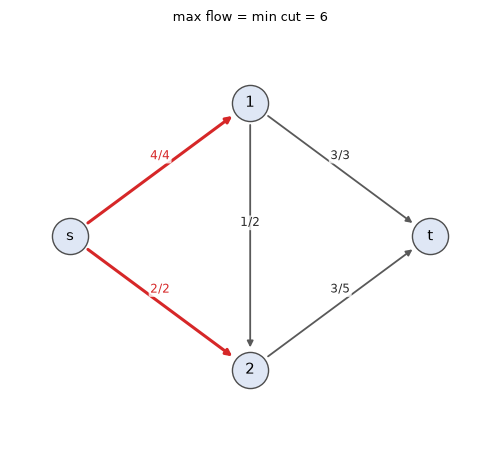

In [12]:
pos53 = {"s": (0.0, 0.0), "1": (1.35, 1.0), "2": (1.35, -1.0), "t": (2.7, 0.0)}
G53 = nx.DiGraph()
for (u, v), cc in zip(edges53, cap53):
    G53.add_edge(u, v, capacity=cc)

flow_val, flow_dict = nx.maximum_flow(G53, "s", "t")
cut_val, (Smin, Tmin) = nx.minimum_cut(G53, "s", "t")
print(f"networkx: max flow {flow_val:.0f}, min cut {cut_val:.0f}, S = {sorted(Smin)}")
assert np.isclose(flow_val, -res53.fun) and np.isclose(cut_val, -res53.fun)
assert np.isclose(cut_capacity(cap53, set(Smin)), -res53.fun)


def draw_flow(ax, caps, f, S, title):
    for k, (u, v) in enumerate(edges53):
        on_cut = u in S and v not in S
        p0, p1 = np.array(pos53[u]), np.array(pos53[v])
        ax.annotate("", xy=p1, xytext=p0,
                    arrowprops=dict(arrowstyle="-|>", lw=2.2 if on_cut else 1.3,
                                    color="tab:red" if on_cut else "0.35",
                                    shrinkA=16, shrinkB=16))
        mid = 0.5 * (p0 + p1) + np.array([0.0, 0.10])
        ax.text(mid[0], mid[1], f"{f[k]:.0f}/{caps[k]:.0f}", ha="center", va="center",
                color="tab:red" if on_cut else "0.15", fontsize=8.5,
                bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.8))
    for nd, p in pos53.items():
        ax.plot(*p, "o", ms=26, mfc="#dfe7f5", mec="0.3", zorder=3)
        ax.text(*p, nd, ha="center", va="center", fontsize=11, zorder=4)
    ax.set_xlim(-0.45, 3.15)
    ax.set_ylim(-1.55, 1.55)
    ax.set_aspect("equal")
    ax.set_axis_off()
    ax.set_title(title, fontsize=9)


fig, ax = plt.subplots(figsize=(7.4, 4.6))
draw_flow(ax, cap53, f53, set(Smin), f"max flow = min cut = {-res53.fun:.0f}")
plt.tight_layout()

In [13]:
mu = -res53.upper.marginals               # capacity multipliers
y53 = res53.eqlin.marginals                 # conservation multipliers
print("mu =", mu, "   y =", y53)
assert (mu >= -1e-9).all()
assert (mu >= b53 + A53.T @ y53 - 1e-9).all()          # dual feasibility
assert np.isclose(mu @ cap53, -res53.fun)              # strong duality


def cut_from_mu(mu):
    """Nodes reachable from s along edges with mu = 0."""
    S = {"s"}
    changed = True
    while changed:
        changed = False
        for k, (u, v) in enumerate(edges53):
            if u in S and mu[k] < 1e-9 and v not in S:
                S.add(v)
                changed = True
    return S


Sdual = cut_from_mu(mu)
print("cut recovered from mu:", sorted(Sdual))
print("edges with mu > 0:", [edges53[k] for k in range(E53) if mu[k] > 1e-9])
assert Sdual == set(Smin)
assert np.isclose(cut_capacity(cap53, Sdual), mu @ cap53)
for k, (u, v) in enumerate(edges53):
    assert (mu[k] > 1e-9) == (u in Sdual and v not in Sdual)

mu = [ 1.  1. -0. -0. -0.]    y = [-0. -0.]
cut recovered from mu: ['s']
edges with mu > 0: [('s', '1'), ('s', '2')]


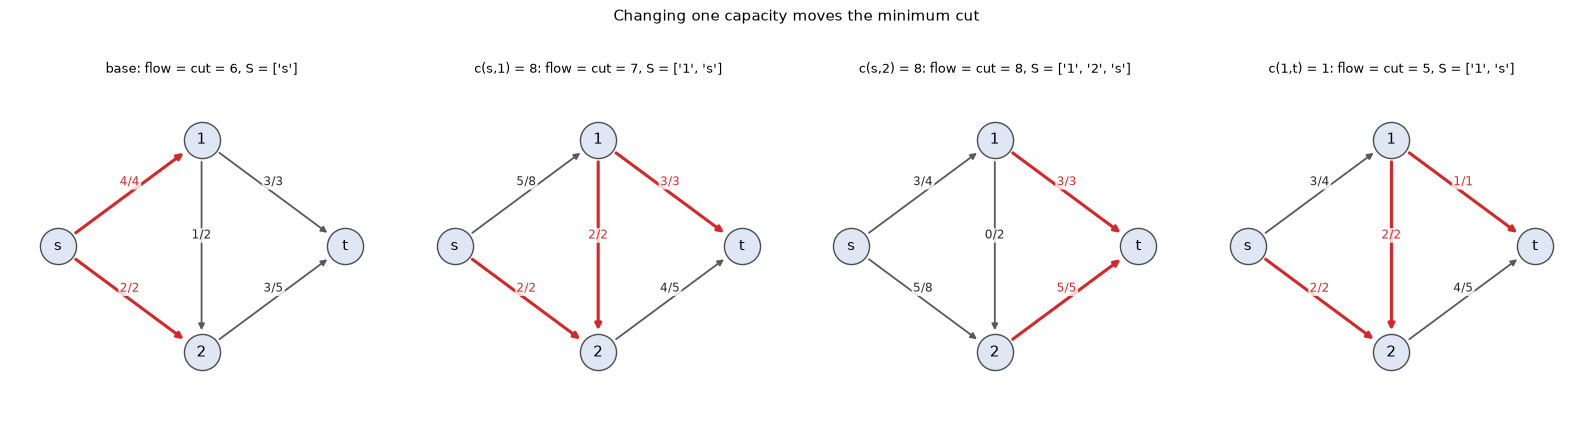

In [14]:
scenarios = [("base", [4, 2, 2, 3, 5]),
             ("c(s,1) = 8", [8, 2, 2, 3, 5]),
             ("c(s,2) = 8", [4, 8, 2, 3, 5]),
             ("c(1,t) = 1", [4, 2, 2, 1, 5])]
fig, axes = plt.subplots(1, 4, figsize=(16.0, 4.2))
for ax, (lab, caps) in zip(axes, scenarios):
    caps = np.array(caps, float)
    r = linprog(-b53, A_eq=A53, b_eq=np.zeros(2), bounds=[(0, cc) for cc in caps],
                method="highs")
    S = cut_from_mu(-r.upper.marginals)
    draw_flow(ax, caps, r.x, S, f"{lab}: flow = cut = {-r.fun:.0f}, S = {sorted(S)}")
fig.suptitle("Changing one capacity moves the minimum cut", y=1.03)
plt.tight_layout()

In [15]:
import ipywidgets as widgets
from ipywidgets import interact


def panel53(c_s1=4.0, c_s2=2.0, c_12=2.0, c_1t=3.0, c_2t=5.0):
    caps = np.array([c_s1, c_s2, c_12, c_1t, c_2t])
    r = linprog(-b53, A_eq=A53, b_eq=np.zeros(2), bounds=[(0, cc) for cc in caps],
                method="highs")
    S = cut_from_mu(-r.upper.marginals)
    fig, ax = plt.subplots(figsize=(6.6, 4.3))
    draw_flow(ax, caps, r.x, S,
              f"max flow = min cut = {-r.fun:.0f},  S = {sorted(S)}")
    plt.show()


def _sl(desc, val):
    return widgets.FloatSlider(value=val, min=0.0, max=10.0, step=0.5, description=desc,
                               continuous_update=False,
                               layout=widgets.Layout(width="320px"))


interact(panel53, c_s1=_sl("c(s,1)", 4.0), c_s2=_sl("c(s,2)", 2.0),
         c_12=_sl("c(1,2)", 2.0), c_1t=_sl("c(1,t)", 3.0), c_2t=_sl("c(2,t)", 5.0));

interactive(children=(FloatSlider(value=4.0, continuous_update=False, description='c(s,1)', layout=Layout(widt…

In [16]:
nodes_big = ["s"] + [str(i) for i in range(1, 7)] + ["t"]
pairs_big = ([("s", str(i)) for i in range(1, 4)]
             + [(str(i), "t") for i in range(1, 4)]
             + [(str(i), str(j)) for i in range(1, 4) for j in range(4, 7)]
             + [(str(j), "t") for j in range(4, 7)]
             + [("1", "2"), ("2", "3"), ("4", "5"), ("5", "6")])
cap_big = rng.integers(1, 11, size=len(pairs_big)).astype(float)

A_big = np.zeros((len(nodes_big) - 2, len(pairs_big)))
for row, v in enumerate(nodes_big[1:-1]):
    for k, (u, w) in enumerate(pairs_big):
        A_big[row, k] += (w == v) - (u == v)
b_big = np.array([1.0 if u == "s" else 0.0 for u, v in pairs_big])

res_big = linprog(-b_big, A_eq=A_big, b_eq=np.zeros(len(nodes_big) - 2),
                  bounds=[(0, c) for c in cap_big], method="highs")
G_big = nx.DiGraph()
for (u, v), cc in zip(pairs_big, cap_big):
    G_big.add_edge(u, v, capacity=cc)
print(f"{len(nodes_big)} nodes, {len(pairs_big)} edges")
print(f"LP max flow = {-res_big.fun:.0f}, networkx max flow = "
      f"{nx.maximum_flow_value(G_big, 's', 't'):.0f}, min cut = "
      f"{nx.minimum_cut_value(G_big, 's', 't'):.0f}")
assert np.isclose(-res_big.fun, nx.maximum_flow_value(G_big, "s", "t"))
assert np.isclose(-res_big.fun, nx.minimum_cut_value(G_big, "s", "t"))
mu_big = -res_big.upper.marginals
y_big = res_big.eqlin.marginals
assert (mu_big >= b_big + A_big.T @ y_big - 1e-9).all()
assert np.isclose(mu_big @ cap_big, -res_big.fun)

8 nodes, 22 edges
LP max flow = 26, networkx max flow = 26, min cut = 26


### Explain

The max-flow LP returns $f=(4,2,1,3,3)$ and value $6$; conservation holds at
both internal nodes and no edge exceeds its capacity. The four cuts
$\{s\},\{s,1\},\{s,2\},\{s,1,2\}$ have capacities $6,7,9,8$, so max flow = min
cut $=6$, and `networkx` returns the same value with $S=\{s\}$. The edges
$s\to1$ and $s\to2$ are saturated ($4/4$ and $2/2$) and are exactly the
edges leaving the minimum cut; $1\to t$ is also saturated ($3/3$) but lies
inside the sink side, so saturation alone does not identify the cut. In the
dual, $\mu=(1,1,0,0,0)$ satisfies $\mu\ge b+A^\top y$ and $\mu^\top c=6$,
and the edges with $\mu>0$ are precisely the cut edges, so the dual optimum is
the min cut and this is strong duality. The flow itself is not unique:
$f_{12}$ can be $1,2$ or $3$ (then $f_{1t}=3,2,1$ and $f_{2t}=3,4,5$),
while the value and the cut are unique; the 8-node, 22-edge random graph gives
flow = cut = $26$.